# 01 · Analisi della validation

## Music Discovery CMAB — Last.fm 1K

Analisi delle **36 configurazioni ufficiali**. La selezione degli iperparametri resta quella congelata prima del test: NDCG@10 a N=100, Average Reward come spareggio e valore numericamente più basso dell'iperparametro come ulteriore spareggio. N=50 e N=200 sono soltanto analisi di sensibilità.

Il notebook legge gli aggregati CSV e i marker dei checkpoint; non carica i JSONL dettagliati in RAM. Gli hash dei payload sono verificati a blocchi. Protocollo temporale: warm-up 2005-10-30–2008-12-31; validation 2009-01-01–2009-02-28; reward horizon 7 giorni; session gap 10 minuti; `N_train` in eventi. La reward è un proxy offline; non è una valutazione IPS/SNIPS né una stima causale.

In [1]:
from __future__ import annotations
import hashlib, json, math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

def root_from(path=None):
    p=(path or Path.cwd()).resolve()
    for q in (p,*p.parents):
        if (q/'experiments/configs/validation.json').is_file(): return q
    raise FileNotFoundError('Repository root not found')
def sha256(path, chunk=8*1024*1024):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        while b:=f.read(chunk): h.update(b)
    return h.hexdigest()
ROOT=root_from()
CFG=ROOT/'experiments/configs/validation.json'
FINAL_CFG=ROOT/'experiments/configs/final_test.json'
MANIFEST=ROOT/'experiments/configs/final_selection_manifest.json'
OUT=ROOT/'experiments/results/validation/ea8616724509-5b076e7a'
CHECKPOINTS=ROOT/'experiments/results/checkpoints/ea8616724509-5b076e7a1cb3'
CSV=OUT/'runs.csv'; JSONL=OUT/'runs.jsonl'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':180,'axes.titlesize':12,'axes.labelsize':10,'legend.frameon':False,'font.size':9})
pd.set_option('display.max_columns',40); pd.set_option('display.width',220)
manifest=json.loads(MANIFEST.read_text(encoding='utf-8'))
config=json.loads(CFG.read_text(encoding='utf-8'))
print(f'Repository: {ROOT}')
print(f'Validation JSONL: {JSONL.stat().st_size/1e9:.2f} GB (not loaded)')

Repository: C:\Users\dales\OneDrive\Desktop\PROGETTO SII\music-discovery-CMAB
Validation JSONL: 9.24 GB (not loaded)


## 1. Completezza e provenienza

Controlliamo 36 righe uniche e completate, la griglia attesa per N, gli identificativi di dataset/configurazione/commit e le date. Per ogni marker `completed` verifichiamo identità e riepilogo contro il CSV; il SHA-256 registrato lega il marker al payload. La ricalcolazione dei 36 payload, circa 9,2 GB, è attivabile con `VERIFY_DETAIL_CHECKSUMS = True` nella cella seguente. L'hash del CSV è confrontato con quello registrato nel manifesto.

In [2]:
unsigned=dict(manifest); manifest_sha=unsigned.pop('manifest_sha256')
computed_manifest_sha=hashlib.sha256(json.dumps(unsigned,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode()).hexdigest()
assert computed_manifest_sha==manifest_sha
config_hash=hashlib.sha256(json.dumps(config,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode()).hexdigest()
assert config_hash==manifest['validation_config_hash']=='ea8616724509edd297d13b5c83a38b14bb758d3148323a51fe123d997ec835f6'
assert manifest['primary_candidate_pool_depth']==100
assert set(manifest['sensitivity_depths_not_used_for_selection'])=={50,200}
assert manifest['selection_rule']['source_phase']=='validation_only' and not manifest['selection_rule']['test_metrics_used_for_selection']
assert manifest['selection_rule']['primary_metric']=='ndcg@10'
runs=pd.read_csv(CSV)
assert len(runs)==36 and runs.run_id.is_unique and set(runs.completion_status)=={'completed'}
assert set(runs.evaluation_phase)=={'validation'} and set(runs.candidate_pool_depth)=={50,100,200}
assert set(runs.dataset_content_hash)=={manifest['dataset_content_hash']}
assert set(runs.configuration_hash)=={config_hash} and set(runs.git_commit)=={manifest['experiment_commit']}
assert set(runs.selection_metric)=={'ndcg@10'} and set(runs.selection_direction)=={'maximize'}
assert runs.experiment_code_digest.nunique()==1
assert set(runs.seed)=={42} and set(runs.random_seed)=={42} and set(runs.N_train_unit)=={'events'}
assert set(runs.reward_horizon_days)=={7} and set(runs.session_gap_minutes)=={10}
assert set(runs.K_values)=={'5,10,20'}
assert set(runs.validation_start)=={'2009-01-01'} and set(runs.validation_end)=={'2009-02-28'}
assert (runs.n_users==562).all() and (runs.n_decisions==runs.n_decision_points_total).all()
assert (runs.skipped_decisions==0).all() and (runs.empty_pool_decisions_excluded==0).all()
assert runs.eligible_user_hash.nunique()==1
assert runs.candidate_pool_digest.nunique()==3 and runs.scaler_digest.nunique()==3
assert (runs.groupby('candidate_pool_depth').candidate_pool_digest.nunique()==1).all()
assert (runs.groupby('candidate_pool_depth').scaler_digest.nunique()==1).all()
expected={'random':1,'popularity':1,'greedy':1,'epsilon_greedy':3,'linucb':6}
for n,g in runs.groupby('candidate_pool_depth'): assert g.policy.value_counts().to_dict()==expected
for a,b in [('catalog_coverage','catalog_coverage@20'),('artist_coverage','artist_coverage@20')]:
    assert np.allclose(runs[a],runs[b],rtol=0,atol=1e-14)
csv_sha=sha256(CSV); assert csv_sha==manifest['validation_results']['aggregate_csv_sha256']
VERIFY_DETAIL_CHECKSUMS=False  # Set True to reread and rehash all ~9.2 GB of per-run JSONL payloads.
markers=sorted(CHECKPOINTS.glob('*.checkpoint.json')); assert len(markers)==36
by_id={}
for i,p in enumerate(markers,1):
    m=json.loads(p.read_text(encoding='utf-8')); ident=m['identity']; rid=ident['run_id']
    assert m['completion_status']=='completed' and rid==p.name.removesuffix('.checkpoint.json') and rid not in by_id
    assert ident['evaluation_phase']=='validation' and ident['configuration_hash']==config_hash
    assert ident['dataset_content_hash']==manifest['dataset_content_hash'] and ident['git_commit']==manifest['experiment_commit']
    assert ident['seed']==42 and ident['random_seed']==42 and ident['candidate_pool_depth'] in {50,100,200}
    assert ident['experiment_code_digest']==runs.loc[runs.run_id==rid,'experiment_code_digest'].iloc[0]
    detail=CHECKPOINTS/m['result_filename']; assert detail.is_file() and isinstance(m.get('result_sha256'),str) and len(m['result_sha256'])==64
    if VERIFY_DETAIL_CHECKSUMS: assert sha256(detail)==m['result_sha256'], f'Checkpoint checksum mismatch: {rid}'
    by_id[rid]=m
    if i%6==0 or i==36: print(f'Checkpoint markers inspected: {i}/36')
assert set(by_id)==set(runs.run_id)
for r in runs.to_dict('records'):
    m=by_id[r['run_id']]; ident=m['identity']; summary=m['summary']
    assert ident['policy']==r['policy'] and ident['candidate_pool_depth']==r['candidate_pool_depth']
    assert ident['random_seed']==r['random_seed'] and ident['experiment_code_digest']==r['experiment_code_digest']
    assert ident['policy_parameters']==json.loads(r['policy_parameters'])
    assert ident['scaler_digest']==r['scaler_digest'] and ident['candidate_pool_digest']==r['candidate_pool_digest']
    for k in ['ndcg@10','average_reward','catalog_coverage@20','artist_coverage@20']:
        assert math.isclose(float(summary[k]),float(r[k]),rel_tol=0,abs_tol=1e-14)
detail_bytes=sum((CHECKPOINTS/m['result_filename']).stat().st_size for m in by_id.values())
assert JSONL.is_file() and JSONL.stat().st_size==detail_bytes+len(runs)
print(f'PASS · {len(runs)}/36 CSV runs; {len(by_id)}/36 verified checkpoint markers')
print('Manifest SHA-256:',manifest_sha,' | CSV SHA-256:',csv_sha)
print('Dataset:',manifest['dataset_content_hash'],' | config:',config_hash,' | commit:',manifest['experiment_commit'])
print(f'JSONL {JSONL.stat().st_size:,} bytes; aggregate size matches per-run details plus Windows newline translation.')

Checkpoint markers inspected: 6/36
Checkpoint markers inspected: 12/36
Checkpoint markers inspected: 18/36
Checkpoint markers inspected: 24/36
Checkpoint markers inspected: 30/36
Checkpoint markers inspected: 36/36
PASS · 36/36 CSV runs; 36/36 verified checkpoint markers
Manifest SHA-256: 93086553c6929c3a0c571a8c1c004744178b701e91b1c88a5038d536c4a21fdd  | CSV SHA-256: 60a08c3da9f51b3818061f915b2302d81359f642daa8ec9a9474e93d9cb49b5d
Dataset: 5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a  | config: ea8616724509edd297d13b5c83a38b14bb758d3148323a51fe123d997ec835f6  | commit: f67c7d9bdf2dfa24de0fe14221adb41c6f1e33a8
JSONL 9,236,301,032 bytes; aggregate size matches per-run details plus Windows newline translation.


## 2. Tabella completa delle configurazioni

Le metriche di ranking e di scoperta sono esplicitamente etichettate con il cut-off. `Average Reward` è una media per azione Top-1 e quindi non dipende da K. La copertura senza suffisso nei dati originali è alias di @20; qui si usano sempre le colonne esplicite.

In [3]:
LABEL={'random':'Random','popularity':'Global Popularity','greedy':'Personalized Greedy','epsilon_greedy':'ε-Greedy','linucb':'LinUCB'}
def parameter(row):
    if row.policy=='linucb': return f"α={row.alpha:g}"
    if row.policy=='epsilon_greedy': return f"ε={row.epsilon:g}"
    if row.policy=='random': return f"seed={int(row.random_seed)}"
    return '—'
runs['policy_label']=runs.policy.map(LABEL); runs['parameter']=runs.apply(parameter,axis=1)
metrics=['ndcg@5','ndcg@10','ndcg@20','average_reward']+[f'{m}@{k}' for m in ['precision','recall','track_novelty','artist_novelty','artist_ild','catalog_coverage','artist_coverage'] for k in (5,10,20)]
all_results=runs[['policy_label','parameter','candidate_pool_depth','run_id']+metrics].sort_values('ndcg@10',ascending=False).reset_index(drop=True)
display(all_results.style.format({c:'{:.6f}' for c in metrics}).set_caption('Validation ufficiale · tutte le 36 configurazioni · ordinate per NDCG@10'))

,policy_label,parameter,candidate_pool_depth,run_id,ndcg@5,ndcg@10,ndcg@20,average_reward,precision@5,precision@10,precision@20,recall@5,recall@10,recall@20,track_novelty@5,track_novelty@10,track_novelty@20,artist_novelty@5,artist_novelty@10,artist_novelty@20,artist_ild@5,artist_ild@10,artist_ild@20,catalog_coverage@5,catalog_coverage@10,catalog_coverage@20,artist_coverage@5,artist_coverage@10,artist_coverage@20
0,LinUCB,α=1,200,fe31dd2969dc4eb1,0.338256,0.293811,0.258536,1.099431,0.450210,0.407692,0.359897,0.039281,0.056510,0.083271,0.393698,0.422045,0.458334,0.019109,0.025086,0.043120,0.728580,0.784500,0.841622,0.179837,0.248958,0.339441,0.233472,0.316609,0.431444
1,LinUCB,α=0.5,200,9602d6b77d55110a,0.338772,0.293727,0.258655,1.099923,0.450114,0.407708,0.359735,0.039403,0.056534,0.083370,0.381804,0.411037,0.450208,0.019167,0.025164,0.043567,0.729786,0.784058,0.841655,0.180184,0.248524,0.339962,0.234740,0.316247,0.431081
2,LinUCB,α=2,200,678c088a1657e9cf,0.337405,0.293715,0.258545,1.097895,0.449619,0.407201,0.359516,0.039146,0.056435,0.083422,0.408864,0.435850,0.469163,0.019304,0.025820,0.043845,0.727844,0.785190,0.842237,0.182181,0.250782,0.341004,0.235827,0.318239,0.430719
3,LinUCB,α=0.25,200,f50040a61590977f,0.338516,0.293681,0.258681,1.100327,0.449903,0.407986,0.359839,0.039408,0.056526,0.083470,0.375053,0.405357,0.445452,0.018981,0.025218,0.043536,0.729625,0.783518,0.841467,0.180010,0.247395,0.339614,0.234559,0.315160,0.431081
4,LinUCB,α=0.1,200,abf62bd45cfe1cfa,0.338604,0.293634,0.258563,1.101288,0.450021,0.408066,0.359758,0.039390,0.056505,0.083379,0.372012,0.402501,0.443298,0.019063,0.025264,0.043491,0.729154,0.783065,0.841116,0.179663,0.247221,0.339441,0.233653,0.315160,0.431081
5,LinUCB,α=2,100,f699daa9d589645c,0.327138,0.285640,0.245263,1.003704,0.405441,0.362577,0.298911,0.037010,0.054551,0.078542,0.546391,0.551388,0.574763,0.028011,0.043548,0.084096,0.789818,0.830548,0.875457,0.268722,0.363636,0.469697,0.331643,0.447062,0.572323
6,LinUCB,α=1,100,7c45c1abf252c215,0.327245,0.285205,0.245220,1.004232,0.406554,0.362666,0.299584,0.037033,0.054463,0.078503,0.530002,0.537982,0.564134,0.028529,0.044780,0.085200,0.787915,0.829067,0.874446,0.264716,0.360502,0.465691,0.328064,0.444676,0.567253
7,LinUCB,α=0.5,100,44f24901edfe1b91,0.326844,0.284789,0.245052,1.003569,0.406764,0.362940,0.299926,0.036902,0.054404,0.078448,0.522023,0.530982,0.558729,0.029234,0.045897,0.086760,0.786700,0.827816,0.873595,0.263149,0.357715,0.461512,0.326275,0.439905,0.561885
8,LinUCB,α=0.1,100,e5b79b2017aae35d,0.326813,0.284684,0.244911,1.004397,0.406828,0.362819,0.299631,0.036807,0.054361,0.078313,0.516219,0.526165,0.555265,0.029942,0.046899,0.088203,0.786432,0.827665,0.873643,0.263149,0.355625,0.459073,0.325082,0.436922,0.558604
9,LinUCB,α=0.25,100,01bc06b2933fca4c,0.326798,0.284530,0.244874,1.003799,0.406904,0.362879,0.299831,0.036934,0.054293,0.078328,0.516143,0.526549,0.555281,0.029669,0.046649,0.087643,0.786274,0.827327,0.873254,0.263323,0.356844,0.460641,0.325082,0.438413,0.560394


## 3. Sweep degli iperparametri

I grafici mostrano NDCG@10 e Average Reward per α ed ε a ciascun N. Il confronto della selezione resta limitato a N=100; gli altri N servono alla sola sensibilità.

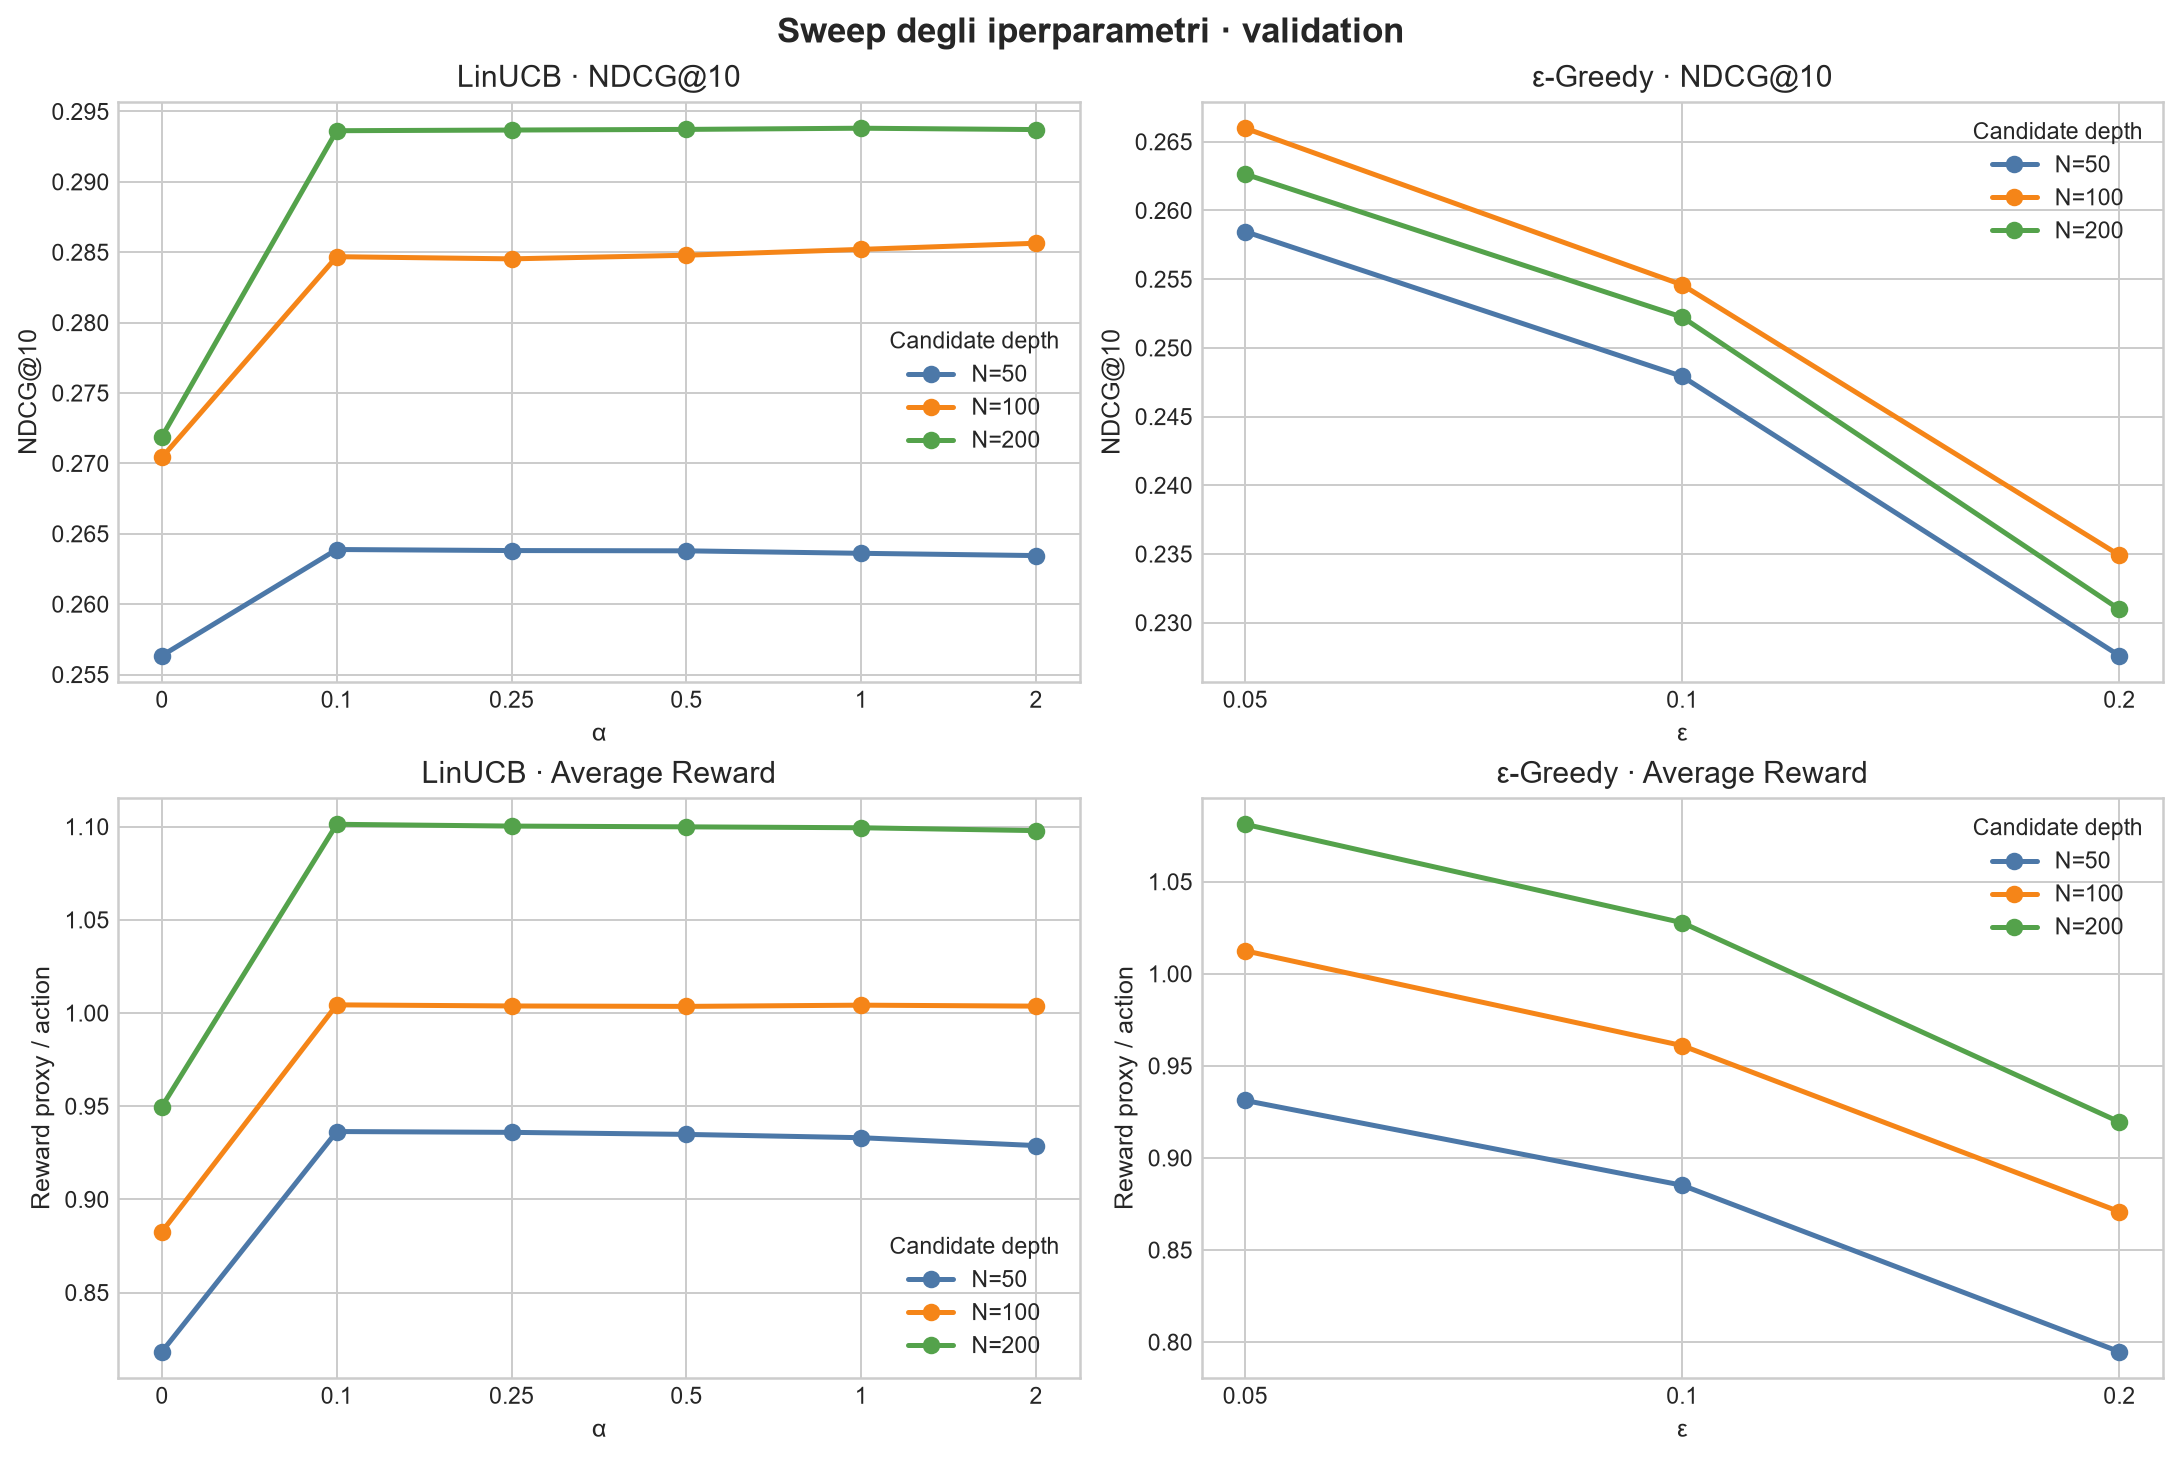

In [4]:
colors={50:'#4C78A8',100:'#F58518',200:'#54A24B'}
alpha_values=sorted(runs.loc[runs.policy=='linucb','alpha'].unique()); alpha_x=np.arange(len(alpha_values))
epsilon_values=sorted(runs.loc[runs.policy=='epsilon_greedy','epsilon'].unique()); epsilon_x=np.arange(len(epsilon_values))
fig,ax=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for n,g in runs[runs.policy=='linucb'].groupby('candidate_pool_depth'):
    g=g.set_index('alpha').reindex(alpha_values)
    ax[0,0].plot(alpha_x,g['ndcg@10'],marker='o',lw=2,color=colors[n],label=f'N={n}')
    ax[1,0].plot(alpha_x,g.average_reward,marker='o',lw=2,color=colors[n],label=f'N={n}')
for n,g in runs[runs.policy=='epsilon_greedy'].groupby('candidate_pool_depth'):
    g=g.set_index('epsilon').reindex(epsilon_values)
    ax[0,1].plot(epsilon_x,g['ndcg@10'],marker='o',lw=2,color=colors[n],label=f'N={n}')
    ax[1,1].plot(epsilon_x,g.average_reward,marker='o',lw=2,color=colors[n],label=f'N={n}')
for a,title,xlab,ylab in [(ax[0,0],'LinUCB · NDCG@10','α','NDCG@10'),(ax[1,0],'LinUCB · Average Reward','α','Reward proxy / action'),(ax[0,1],'ε-Greedy · NDCG@10','ε','NDCG@10'),(ax[1,1],'ε-Greedy · Average Reward','ε','Reward proxy / action')]:
    a.set(title=title,xlabel=xlab,ylabel=ylab); a.legend(title='Candidate depth')
ax[0,0].set_xticks(alpha_x,[f'{v:g}' for v in alpha_values]); ax[1,0].set_xticks(alpha_x,[f'{v:g}' for v in alpha_values])
ax[0,1].set_xticks(epsilon_x,[f'{v:g}' for v in epsilon_values]); ax[1,1].set_xticks(epsilon_x,[f'{v:g}' for v in epsilon_values])
fig.suptitle('Sweep degli iperparametri · validation',fontsize=14,fontweight='bold'); plt.show()

## 4. Confronto a N=100 e sensibilità alle dimensioni del pool

Per la selezione a N=100 si usano i run ID nel manifesto. Per visualizzare la sensibilità, si prende il migliore parametro osservato entro ciascuna famiglia e profondità: è un riepilogo descrittivo e non modifica la scelta congelata.

,policy,run_id,ndcg@10,average_reward,track_novelty@10,artist_novelty@10,artist_ild@10,catalog_coverage@10,artist_coverage@10
23,LinUCB,f699daa9d589645c,0.285640,1.003704,0.551388,0.043548,0.830548,0.363636,0.447062
14,Personalized Greedy,4ee1c7cd8ab862b1,0.276427,1.060560,0.448995,0.000000,0.756039,0.258447,0.284223
15,ε-Greedy,93648fba05cb426d,0.265987,1.012495,0.470583,0.023278,0.767605,0.472309,0.575902
12,Random,68ee5a6012e54aef,0.066118,0.097295,0.879464,0.467697,0.993623,0.820794,0.925142
13,Global Popularity,d1b463f44b968420,0.041145,0.308597,0.668625,0.238711,0.000000,0.003483,0.000298


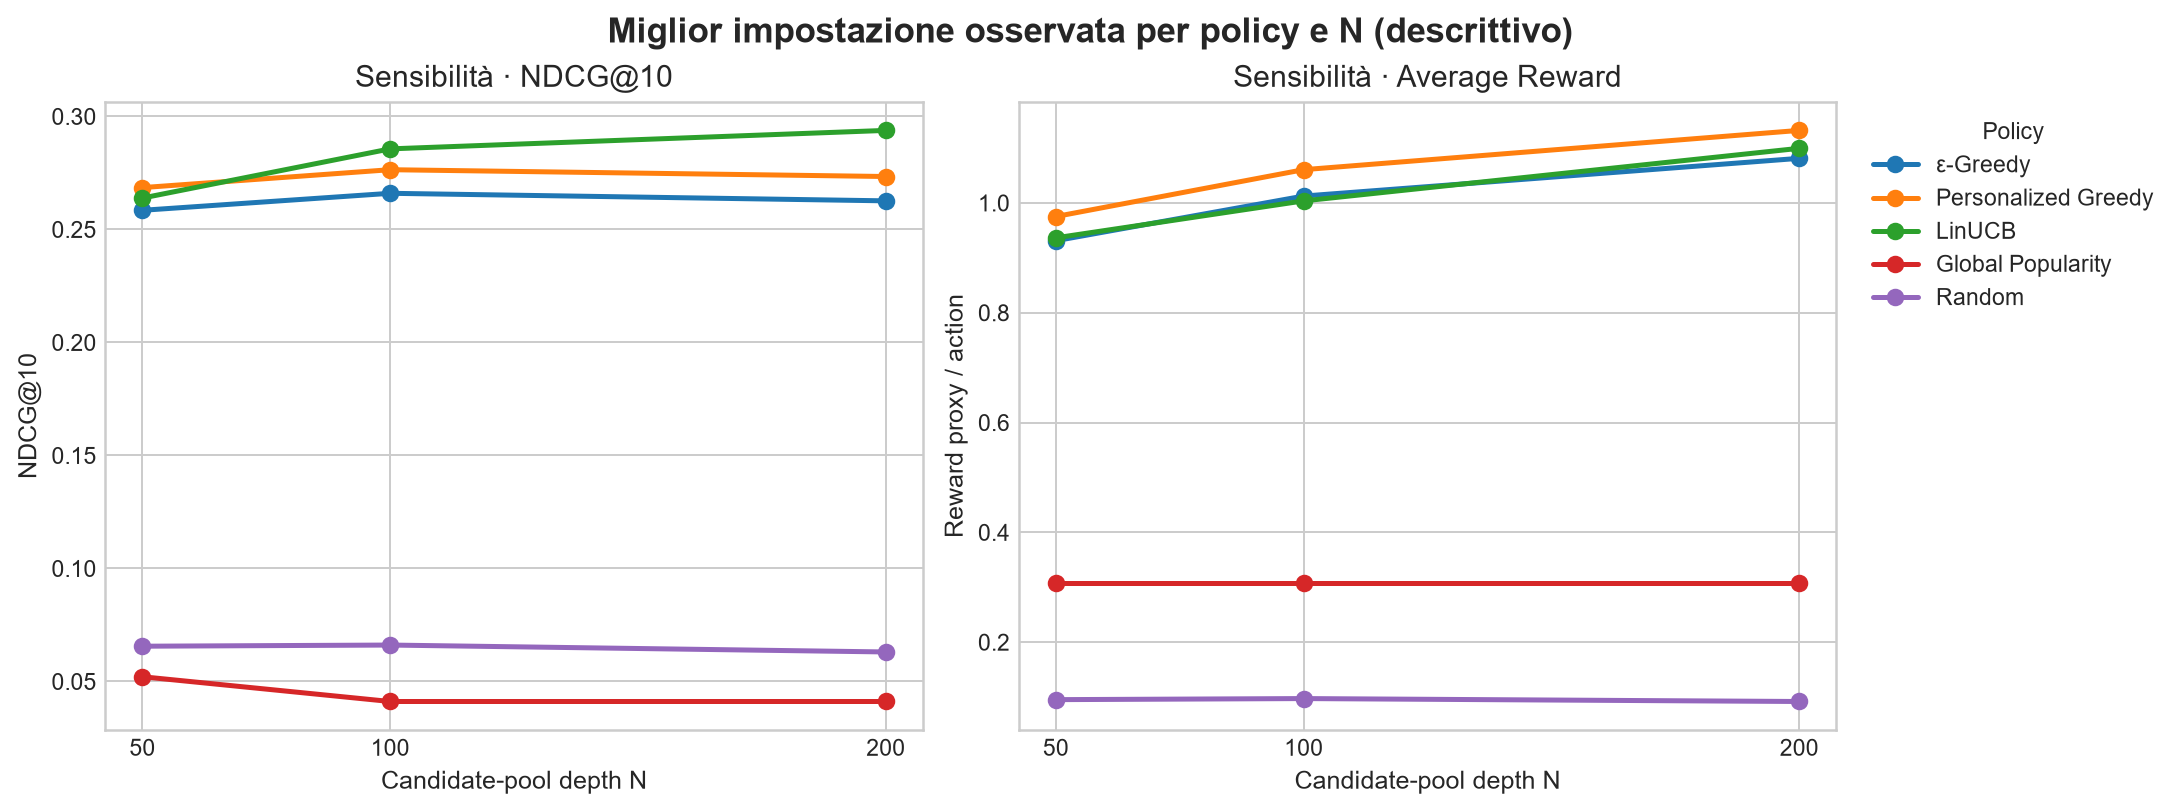

,policy,candidate_pool_depth,alpha,epsilon,ndcg@10,average_reward
1,Global Popularity,50,nan,nan,0.052096,0.308597
7,LinUCB,50,0.10,nan,0.263883,0.936416
2,Personalized Greedy,50,nan,nan,0.268507,0.975219
0,Random,50,nan,nan,0.065606,0.095330
3,ε-Greedy,50,nan,0.05,0.258463,0.931208
13,Global Popularity,100,nan,nan,0.041145,0.308597
23,LinUCB,100,2.00,nan,0.285640,1.003704
14,Personalized Greedy,100,nan,nan,0.276427,1.060560
12,Random,100,nan,nan,0.066118,0.097295
15,ε-Greedy,100,nan,0.05,0.265987,1.012495


In [5]:
selected=[]
for p,item in manifest['selected_validation_runs'].items():
    r=runs.loc[runs.run_id==item['run_id']]; assert len(r)==1 and int(r.iloc[0].candidate_pool_depth)==100
    assert json.loads(r.iloc[0].policy_parameters)==item['parameters']
    for metric in ['ndcg@10','average_reward']:
        assert math.isclose(float(r.iloc[0][metric]),float(manifest['validation_scores_at_n100'][p][metric]),rel_tol=0,abs_tol=1e-14)
    selected.append(r.iloc[0])
selected=pd.DataFrame(selected)
for p,col,val in [('linucb','alpha',manifest['final_parameters']['linucb']['alpha']),('epsilon_greedy','epsilon',manifest['final_parameters']['epsilon_greedy']['epsilon'])]:
    g=runs[(runs.policy==p)&(runs.candidate_pool_depth==100)]
    winner=g.sort_values(['ndcg@10','average_reward',col],ascending=[False,False,True]).iloc[0]
    assert float(winner[col])==float(val)
main=selected[['policy','run_id','ndcg@10','average_reward','track_novelty@10','artist_novelty@10','artist_ild@10','catalog_coverage@10','artist_coverage@10']].copy()
main['policy']=main.policy.map(LABEL); display(main.sort_values('ndcg@10',ascending=False).style.format({c:'{:.6f}' for c in main.select_dtypes('number').columns}).set_caption('Configurazioni congelate · N=100'))

best=[]
for (p,n),g in runs.groupby(['policy','candidate_pool_depth']):
    col='alpha' if p=='linucb' else 'epsilon' if p=='epsilon_greedy' else None
    w=g.sort_values(['ndcg@10','average_reward',col],ascending=[False,False,True]).iloc[0] if col else g.iloc[0]
    best.append(w)
best=pd.DataFrame(best)
fig,axes=plt.subplots(1,2,figsize=(12,4.4),constrained_layout=True)
for p,g in best.groupby('policy'):
    g=g.sort_values('candidate_pool_depth'); label=LABEL[p]
    axes[0].plot(g.candidate_pool_depth,g['ndcg@10'],marker='o',lw=2,label=label)
    axes[1].plot(g.candidate_pool_depth,g.average_reward,marker='o',lw=2,label=label)
axes[0].set(title='Sensibilità · NDCG@10',xlabel='Candidate-pool depth N',ylabel='NDCG@10',xticks=[50,100,200])
axes[1].set(title='Sensibilità · Average Reward',xlabel='Candidate-pool depth N',ylabel='Reward proxy / action',xticks=[50,100,200]); axes[1].legend(title='Policy',bbox_to_anchor=(1.02,1),loc='upper left')
fig.suptitle('Miglior impostazione osservata per policy e N (descrittivo)',fontsize=14,fontweight='bold'); plt.show()
best_summary=best[['policy','candidate_pool_depth','alpha','epsilon','ndcg@10','average_reward']].copy()
best_summary['policy']=best_summary.policy.map(LABEL)
display(best_summary.sort_values(['candidate_pool_depth','policy']).style.format({'alpha':'{:.2f}','epsilon':'{:.2f}','ndcg@10':'{:.6f}','average_reward':'{:.6f}'}).set_caption('Riepilogo per policy e profondità N (miglior iperparametro descrittivo)'))

## 5. Novelty, ILD e coverage ai cut-off 5, 10 e 20

Track Novelty e Catalog Coverage sono track/item-level. Artist Novelty, Artist ILD e Artist Coverage sono artist-level. K indica inizialmente le Top-K track; le metriche artist-level valutano la sequenza degli artisti distinti estratti da quelle track.

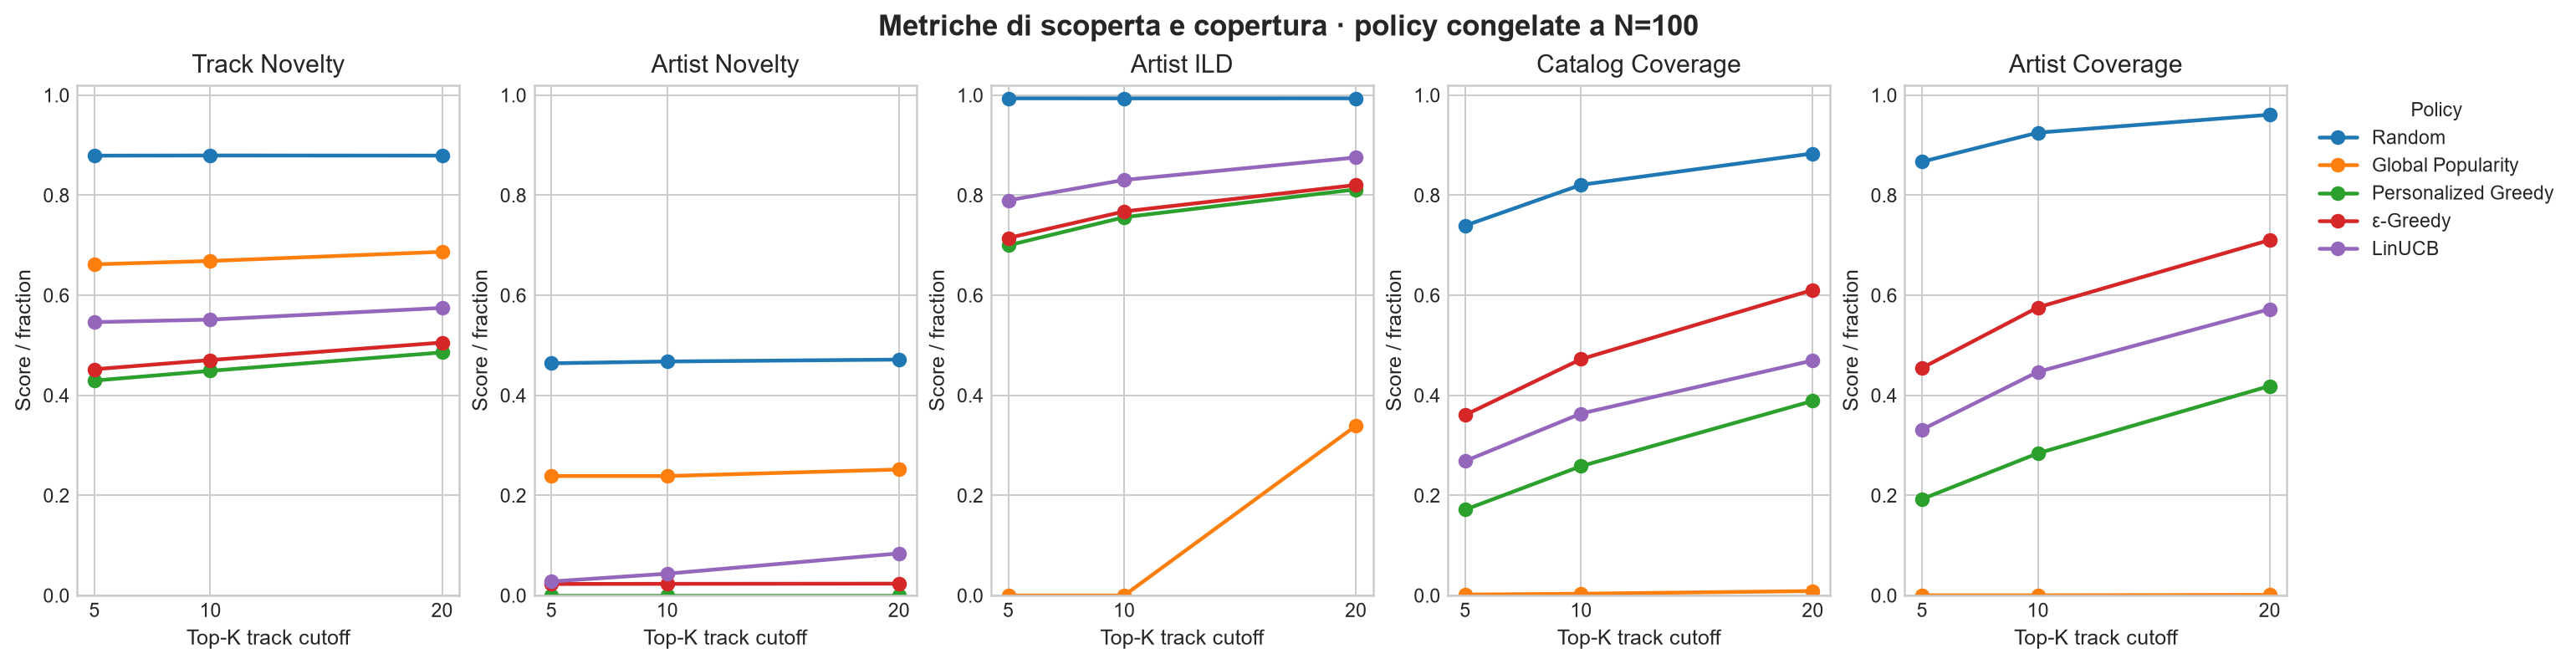

In [6]:
fig,axes=plt.subplots(1,5,figsize=(17,4.3),sharex=True,constrained_layout=True)
series=[('track_novelty','Track Novelty'),('artist_novelty','Artist Novelty'),('artist_ild','Artist ILD'),('catalog_coverage','Catalog Coverage'),('artist_coverage','Artist Coverage')]
for a,(prefix,title) in zip(axes,series):
    for _,r in selected.iterrows():
        a.plot([5,10,20],[r[f'{prefix}@{k}'] for k in (5,10,20)],marker='o',lw=1.8,label=LABEL[r.policy])
    a.set(title=title,xlabel='Top-K track cutoff',ylabel='Score / fraction',xticks=[5,10,20],ylim=(0,1.02))
axes[-1].legend(title='Policy',bbox_to_anchor=(1.04,1),loc='upper left')
fig.suptitle('Metriche di scoperta e copertura · policy congelate a N=100',fontsize=14,fontweight='bold'); plt.show()

## 6. Interpretazione

La scelta congelata usa esclusivamente la validation N=100 e i criteri registrati nel manifesto. N=50 e N=200 non concorrono alla selezione. I valori descrivono il comportamento delle policy in una simulazione sequenziale offline; Last.fm 1K non contiene raccomandazioni mostrate né feedback osservati dopo un'esposizione. La reward proxy non supporta conclusioni causali. Le differenze numeriche qui riportate non sono dichiarate statisticamente significative.

In [7]:
selection=pd.DataFrame([{'Policy':LABEL[p],'Run ID':item['run_id'],'Parametri':json.dumps(item['parameters'],sort_keys=True),'N':100,'NDCG@10':manifest['validation_scores_at_n100'][p]['ndcg@10'],'Average Reward':manifest['validation_scores_at_n100'][p]['average_reward']} for p,item in manifest['selected_validation_runs'].items()]).sort_values('NDCG@10',ascending=False)
display(selection.style.format({'NDCG@10':'{:.6f}','Average Reward':'{:.6f}'}).set_caption('Selezione congelata prima del test'))
print('Analisi validation completata; nessun esperimento è stato eseguito.')

Analisi validation completata; nessun esperimento è stato eseguito.


,Policy,Run ID,Parametri,N,NDCG@10,Average Reward
4,LinUCB,f699daa9d589645c,"{""alpha"": 2.0}",100,0.285640,1.003704
2,Personalized Greedy,4ee1c7cd8ab862b1,{},100,0.276427,1.060560
3,ε-Greedy,93648fba05cb426d,"{""epsilon"": 0.05, ""random_seed"": 42}",100,0.265987,1.012495
0,Random,68ee5a6012e54aef,"{""random_seed"": 42}",100,0.066118,0.097295
1,Global Popularity,d1b463f44b968420,{},100,0.041145,0.308597
